# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

# Carga del archivo en un DataFrame llamado df
df = pd.read_csv(DATA_PATH)
print("Datos cargados:", df.shape)
df.head()


Datos cargados: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
# Profiling: forma, tipos, nulos, duplicados y distribución del target
print("Forma:", df.shape)
print("\nTipos de dato:")
print(df.dtypes)

print("\nValores nulos por columna:")
print(df.isnull().sum())

n_dup = df.duplicated().sum()
print("\nFilas duplicadas:", n_dup)

print("\nDistribución del target:")
print(df["target"].value_counts().sort_index())
print("\nProporciones del target:")
print(df["target"].value_counts(normalize=True).sort_index().round(3))

print("\nResumen estadístico:")
df.describe().T


Forma: (178, 14)

Tipos de dato:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

Valores nulos por columna:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                      

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


**Conclusión de calidad:**

> El dataset tiene 178 filas y 14 columnas (13 features numéricas + `target`).
> **No hay valores nulos ni filas duplicadas**, y todas las features son
> numéricas (`float64`), por lo que no se requiere imputación ni codificación
> de categóricas. El `target` tiene 3 clases (0, 1, 2) con un desbalance leve
> (aprox. 40 % / 33 % / 27 %), suficiente para justificar un split
> **estratificado**. Decisión: no se eliminan filas; se conserva todo el
> conjunto y se procede al split estratificado.


## 2. Split train/test

In [5]:
# Split estratificado 80/20
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)
print("Train:", train_df.shape, " Test:", test_df.shape)


Train: (142, 14)  Test: (36, 14)


In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

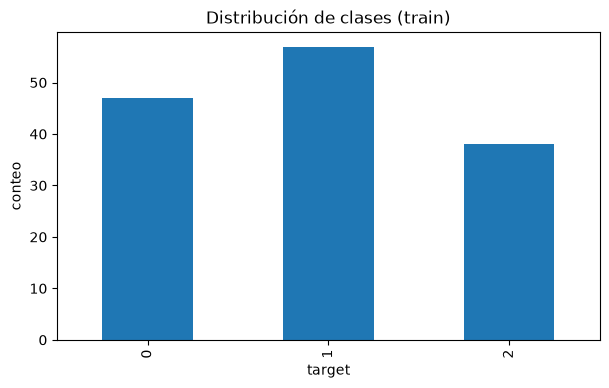

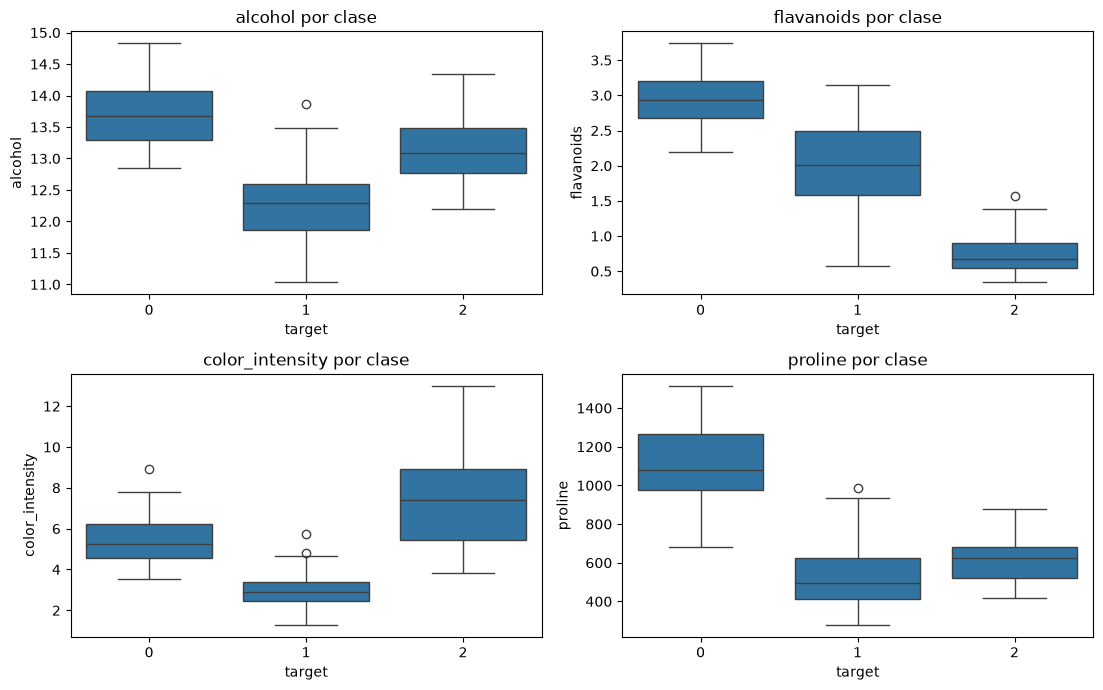

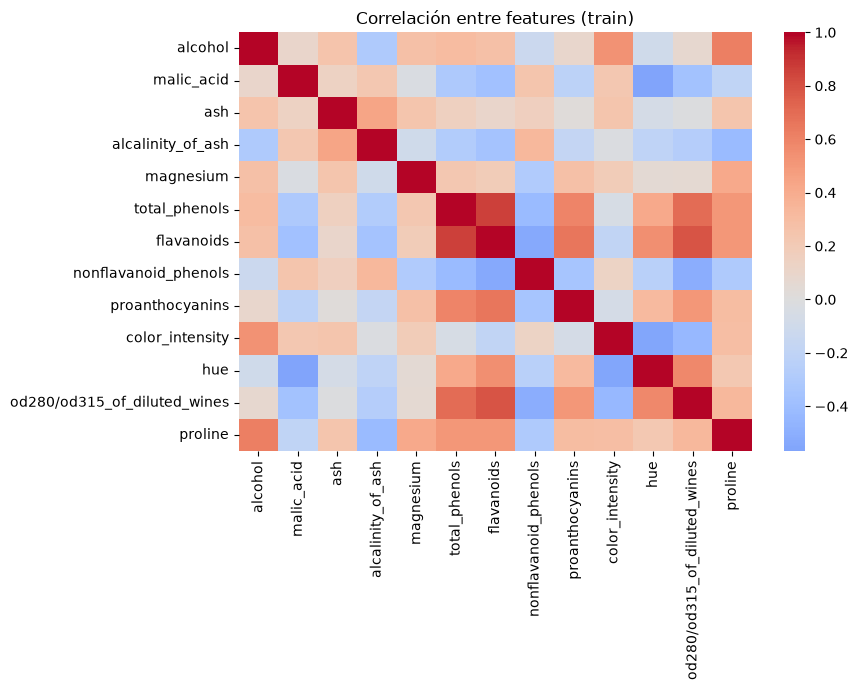

Correlación |feature-target| (train):
flavanoids                      0.870
od280/od315_of_diluted_wines    0.784
total_phenols                   0.714
proline                         0.639
hue                             0.606
alcalinity_of_ash               0.508
proanthocyanins                 0.481
nonflavanoid_phenols            0.477
malic_acid                      0.418
alcohol                         0.332
color_intensity                 0.269
magnesium                       0.208
ash                             0.045
Name: target, dtype: float64


In [7]:
# EDA SOLO sobre train_df (no se toca test)
# 1) Distribución de clases
fig, ax = plt.subplots()
train_df["target"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Distribución de clases (train)")
ax.set_xlabel("target"); ax.set_ylabel("conteo")
plt.show()

# 2) Boxplots de algunas variables relevantes por clase
feats = ["alcohol", "flavanoids", "color_intensity", "proline"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), feats):
    sns.boxplot(data=train_df, x="target", y=col, ax=ax)
    ax.set_title(f"{col} por clase")
plt.tight_layout(); plt.show()

# 3) Mapa de correlaciones entre features
corr = train_df.drop(columns=["target"]).corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlación entre features (train)")
plt.tight_layout(); plt.show()

# Correlación (en valor absoluto) de cada feature con el target
corr_target = (
    train_df.corr(numeric_only=True)["target"].drop("target").abs().sort_values(ascending=False)
)
print("Correlación |feature-target| (train):")
print(corr_target.round(3))


**Hallazgos:**

1. **`flavanoids`, `od280/od315_of_diluted_wines` y `proline` son muy
   discriminantes:** sus distribuciones por clase están claramente separadas
   (altos valores de correlación con el target), por lo que serán features
   importantes para el modelo.
2. **Las escalas de las features son muy distintas** (p. ej. `proline` está en
   cientos/miles mientras `hue` ronda ~1): esto hace necesario **estandarizar**
   para modelos sensibles a la escala (KNN, regresión logística).
3. **Clases razonablemente separables pero con desbalance leve** (clase 1 es la
   mayoritaria): conviene usar split estratificado y reportar F1 macro, no solo
   accuracy, para no favorecer a la clase mayoritaria.


## 4. Persistencia de datos y contrato

In [8]:
# Reiniciar índices y guardar sin el índice
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

# Contrato de datos
features = [c for c in df.columns if c != "target"]
data_contract = {
    "target": "target",
    "features": features,
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "n_classes": int(df["target"].nunique()),
    "source": "data/raw/wine.csv",
}
(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(data_contract, indent=2), encoding="utf-8"
)
print("Guardados train.csv, test.csv y data_contract.json")
print(json.dumps(data_contract, indent=2))


Guardados train.csv, test.csv y data_contract.json
{
  "target": "target",
  "features": [
    "alcohol",
    "malic_acid",
    "ash",
    "alcalinity_of_ash",
    "magnesium",
    "total_phenols",
    "flavanoids",
    "nonflavanoid_phenols",
    "proanthocyanins",
    "color_intensity",
    "hue",
    "od280/od315_of_diluted_wines",
    "proline"
  ],
  "random_state": 42,
  "test_size": 0.2,
  "n_classes": 3,
  "source": "data/raw/wine.csv"
}


In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [ ] Cargué el CSV desde `data/raw`.
- [ ] Revisé calidad y distribución de la clase.
- [ ] Realicé un split estratificado.
- [ ] No exploré el conjunto de test.
- [ ] Guardé los tres artefactos requeridos.